In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
from scipy.stats import lognorm
from math import ceil

## Data

In [2]:
data1 = pd.read_excel('../data/raw/wer_MC_data_org.xlsx', sheet_name='CSTB_processed')
data2 = pd.read_excel('../data/raw/wer_MC_data_org.xlsx', sheet_name='GBDB_data')
important_columns = ['bldg_use_type', 'bldg_use_subtype', 'bldg_project_status', 'site_country', 'bldg_floors_ag', 'bldg_floors_bg', 'bldg_struct_type', 'bldg_roof_type', 'GHG_sum_em_m2a']
data1 = data1[important_columns]
data2 = data2[important_columns]
data = pd.concat([data1, data2], ignore_index=True)
print(data.shape)
data = data.drop_duplicates()
print(data.shape)
data

(1781, 9)
(1673, 9)


,bldg_use_type,bldg_use_subtype,bldg_project_status,site_country,bldg_floors_ag,bldg_floors_bg,bldg_struct_type,bldg_roof_type,GHG_sum_em_m2a
0,Residential,Single family house,New Built,France,0.0,0.0,massive brick,Other,11.430481
1,Residential,Single family house,New Built,France,0.0,0.0,massive brick,Gable or saddle roof,11.222277
2,Residential,Single family house,New Built,France,0.0,0.0,massive brick,Gable or saddle roof,11.183415
3,Residential,Multi-family house,New Built,France,4.0,1.0,massive concrete,Flat roof,13.303147
4,Residential,Multi-family house,New Built,France,4.0,1.0,massive concrete,Flat roof,13.071612
...,...,...,...,...,...,...,...,...,...
1776,Residential,Single family house,New Built,USA,1.0,NaN,frame concrete,No data,3.490000
1777,Residential,Single family house,New Built,USA,1.0,NaN,frame wood,No data,2.680000
1778,Residential,Single family house,New Built,USA,1.0,NaN,frame steel,No data,2.810000
1779,Residential,Single family house,New Built,USA,2.0,1.0,frame wood,Gable or saddle roof,6.680000


In [3]:
no_nulls = data[data.notnull().all(axis=1)]
print(no_nulls.shape)
no_nulls = no_nulls[~no_nulls.astype(str).apply(lambda col: col.str.contains("No data", regex=False)).any(axis=1)]
print(no_nulls.shape)
no_nulls

(629, 9)
(600, 9)


,bldg_use_type,bldg_use_subtype,bldg_project_status,site_country,bldg_floors_ag,bldg_floors_bg,bldg_struct_type,bldg_roof_type,GHG_sum_em_m2a
0,Residential,Single family house,New Built,France,0.0,0.0,massive brick,Other,11.430481
1,Residential,Single family house,New Built,France,0.0,0.0,massive brick,Gable or saddle roof,11.222277
2,Residential,Single family house,New Built,France,0.0,0.0,massive brick,Gable or saddle roof,11.183415
3,Residential,Multi-family house,New Built,France,4.0,1.0,massive concrete,Flat roof,13.303147
4,Residential,Multi-family house,New Built,France,4.0,1.0,massive concrete,Flat roof,13.071612
...,...,...,...,...,...,...,...,...,...
1761,Non-residential,Office,New Built,USA,8.0,3.0,frame wood,Flat roof,6.670400
1772,Non-residential,Office,New Built,USA,8.0,3.0,frame concrete,Flat roof,9.007200
1773,Non-residential,Office,New Built,USA,8.0,3.0,frame wood,Flat roof,6.550600
1779,Residential,Single family house,New Built,USA,2.0,1.0,frame wood,Gable or saddle roof,6.680000


In [4]:
data_basis = no_nulls.copy()

def get_struct_type(original_type):
    """Get our defined structure types from the data structure types."""
    if "wood" in original_type.lower():
        return "Wood"
    elif "concrete" in original_type.lower():
        return "Concrete"
    if "brick" in original_type.lower():
        return "Brick"
    else:
        return None

# Create new columns
data_basis['use_type'] = np.where(
    data_basis['bldg_use_type'] == 'Residential', 
    data_basis['bldg_use_subtype'], 
    data_basis['bldg_use_type']
)
data_basis['struct_type'] = data_basis['bldg_struct_type'].apply(get_struct_type)
data_basis["GHG_sum_em_m2a"] = np.round(pd.to_numeric(data_basis["GHG_sum_em_m2a"], errors='coerce'), 1)


# Filter columns
data_basis = data_basis[data_basis['bldg_project_status'] == 'New Built']
data_basis = data_basis[data_basis['site_country'] == 'France']
data_basis = data_basis[data_basis['bldg_floors_ag'] <= 2]
data_basis = data_basis[data_basis['struct_type'].notnull()]

data_basis['bldg_floors_ag'] = data_basis['bldg_floors_ag'].astype(str)
data_basis['bldg_floors_bg'] = data_basis['bldg_floors_bg'].astype(str)

# Drop columns
cleaned_filtered_data = data_basis.drop(columns=['bldg_use_type', 'bldg_use_subtype', 'bldg_project_status', 'site_country', 'bldg_struct_type'])
cleaned_filtered_data

,bldg_floors_ag,bldg_floors_bg,bldg_roof_type,GHG_sum_em_m2a,use_type,struct_type
0,0.0,0.0,Other,11.4,Single family house,Brick
1,0.0,0.0,Gable or saddle roof,11.2,Single family house,Brick
2,0.0,0.0,Gable or saddle roof,11.2,Single family house,Brick
5,0.0,0.0,Gable or saddle roof,11.3,Single family house,Brick
6,0.0,0.0,Gable or saddle roof,10.0,Single family house,Brick
...,...,...,...,...,...,...
1304,2.0,1.0,Gable or saddle roof,12.4,Single family house,Concrete
1354,1.0,1.0,Other,12.3,Single family house,Brick
1368,2.0,1.0,Gable or saddle roof,11.7,Single family house,Brick
1370,1.0,1.0,Other,12.5,Single family house,Brick


## Target variable

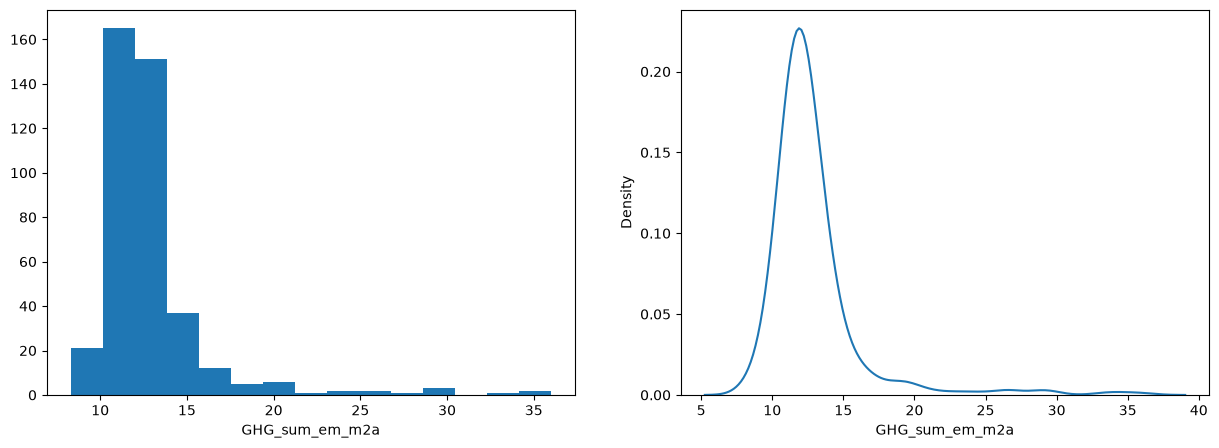

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(cleaned_filtered_data['GHG_sum_em_m2a'], bins=15)
axes[0].set_xlabel('GHG_sum_em_m2a')

sns.kdeplot(data=cleaned_filtered_data, x='GHG_sum_em_m2a', ax=axes[1])
axes[1].set_xlabel('GHG_sum_em_m2a')

plt.show()

## Possible parameters

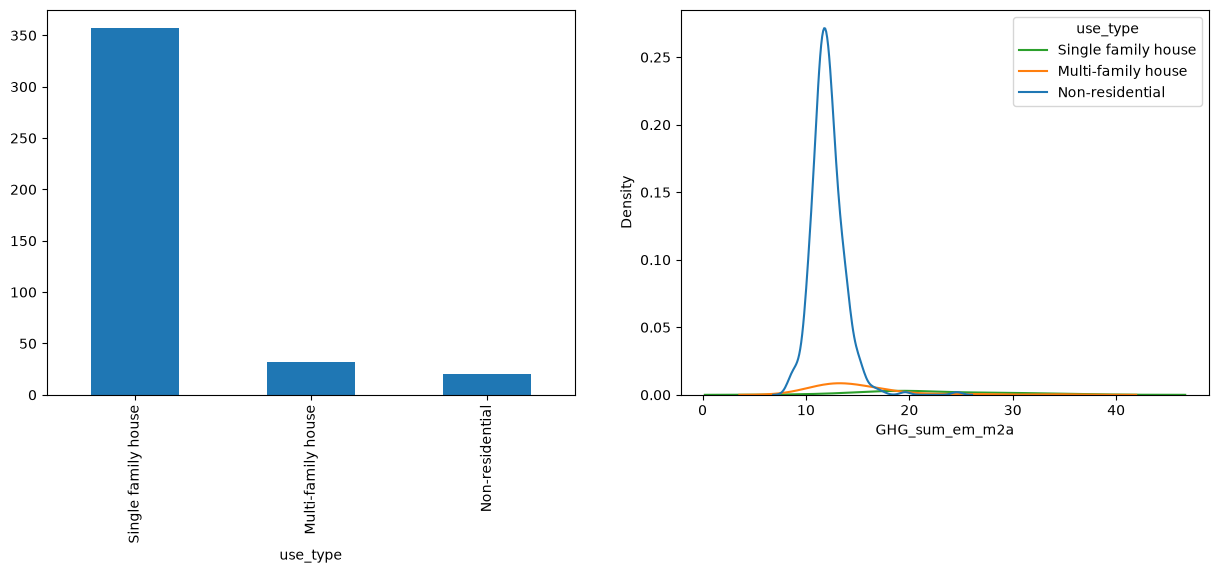

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cleaned_filtered_data["use_type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_xlabel("use_type")

sns.kdeplot(data=cleaned_filtered_data, x='GHG_sum_em_m2a', hue='use_type', ax=axes[1])
axes[1].set_xlabel('GHG_sum_em_m2a')
axes[1].legend(cleaned_filtered_data["use_type"].unique(), title="use_type")

plt.show()

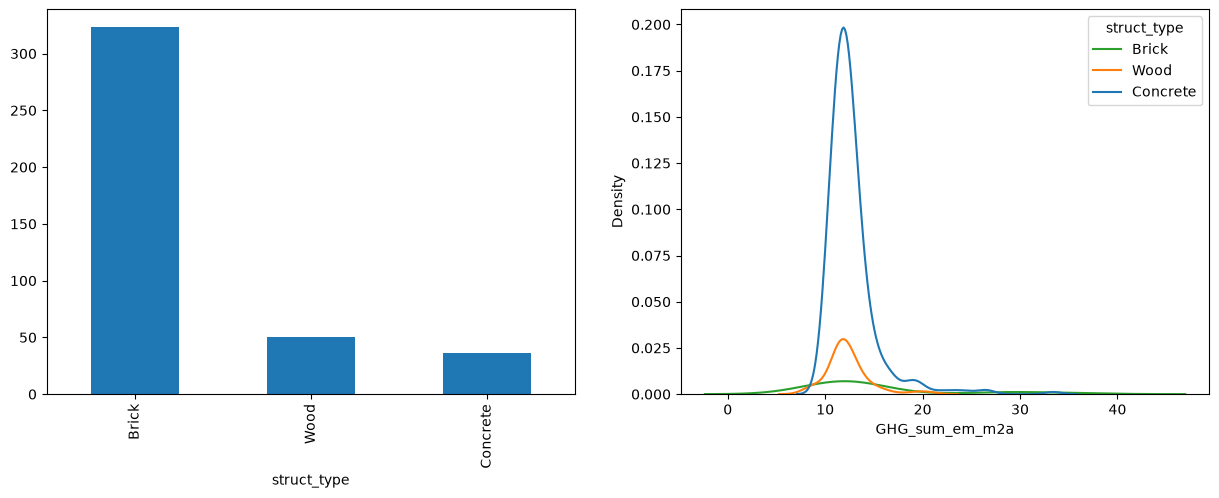

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cleaned_filtered_data["struct_type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_xlabel("struct_type")

sns.kdeplot(data=cleaned_filtered_data, x='GHG_sum_em_m2a', hue='struct_type', ax=axes[1])
axes[1].set_xlabel('GHG_sum_em_m2a')
axes[1].legend(cleaned_filtered_data["struct_type"].unique(), title="struct_type")

plt.show()

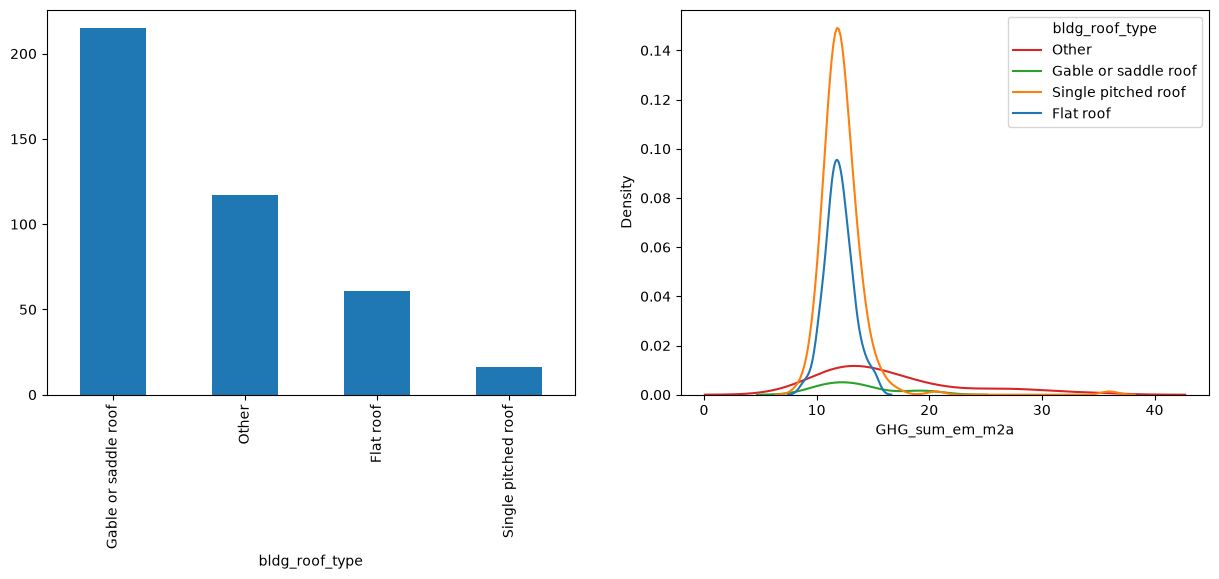

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cleaned_filtered_data["bldg_roof_type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_xlabel("bldg_roof_type")

sns.kdeplot(data=cleaned_filtered_data, x='GHG_sum_em_m2a', hue='bldg_roof_type', ax=axes[1])
axes[1].set_xlabel('GHG_sum_em_m2a')
axes[1].legend(cleaned_filtered_data["bldg_roof_type"].unique(), title="bldg_roof_type")

plt.show()

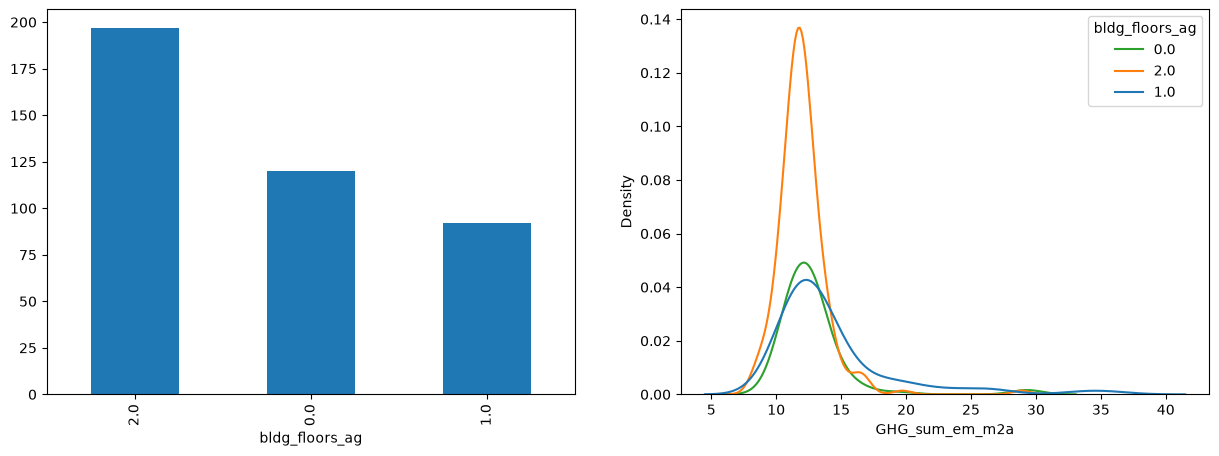

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cleaned_filtered_data["bldg_floors_ag"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_xlabel("bldg_floors_ag")

sns.kdeplot(data=cleaned_filtered_data, x='GHG_sum_em_m2a', hue='bldg_floors_ag', ax=axes[1])
axes[1].set_xlabel('GHG_sum_em_m2a')
axes[1].legend(cleaned_filtered_data["bldg_floors_ag"].unique(), title="bldg_floors_ag")

plt.show()

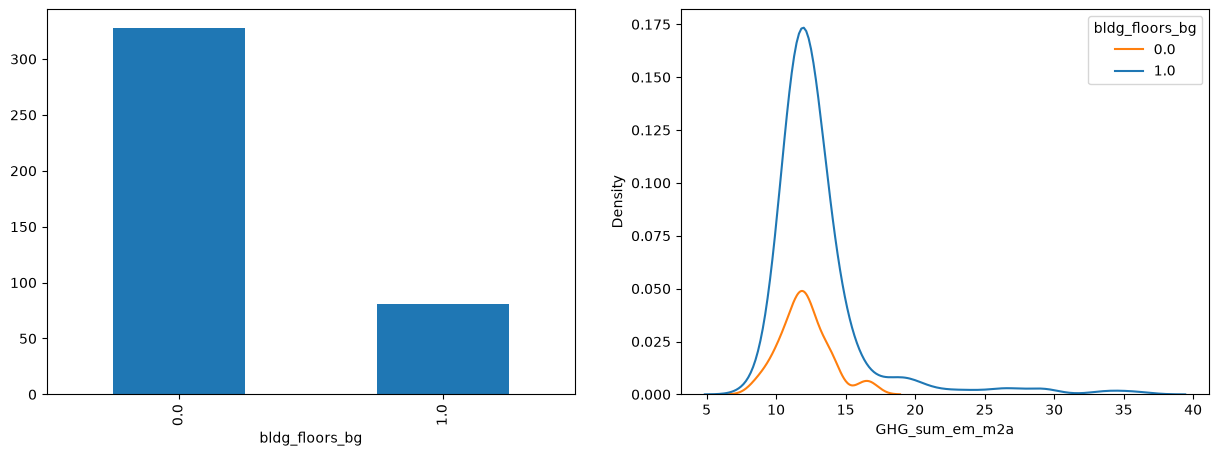

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cleaned_filtered_data["bldg_floors_bg"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_xlabel("bldg_floors_bg")

sns.kdeplot(data=cleaned_filtered_data, x='GHG_sum_em_m2a', hue='bldg_floors_bg', ax=axes[1])
axes[1].set_xlabel('GHG_sum_em_m2a')
axes[1].legend(cleaned_filtered_data["bldg_floors_bg"].unique(), title="bldg_floors_bg")

plt.show()

Wir werfen diese Materiale vorerst mal, da wir schon einen Struct-Type mit Material haben.

## Correlation

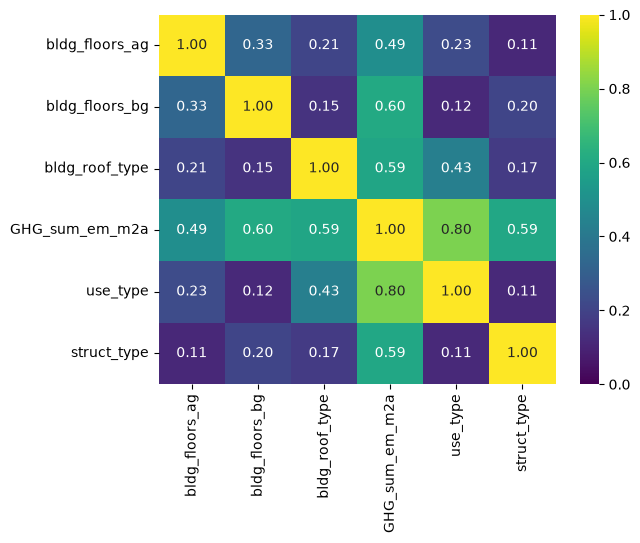

In [11]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))) if min(r, k) > 1 else np.nan

cols = cleaned_filtered_data.columns
corr = pd.DataFrame(
    [[cramers_v(cleaned_filtered_data[a], cleaned_filtered_data[b]) for b in cols] for a in cols],
    index=cols, columns=cols,
)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.show()